In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from scipy import stats

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv(r"C:\Users\Yadu krishna.M\Downloads\archive\Student_Performance.csv")
print("data loaded sucessfully")

data loaded sucessfully


       Hours Studied  Previous Scores   Sleep Hours  \
count   10000.000000     10000.000000  10000.000000   
mean        4.992900        69.445700      6.530600   
std         2.589309        17.343152      1.695863   
min         1.000000        40.000000      4.000000   
25%         3.000000        54.000000      5.000000   
50%         5.000000        69.000000      7.000000   
75%         7.000000        85.000000      8.000000   
max         9.000000        99.000000      9.000000   

       Sample Question Papers Practiced  Performance Index  
count                      10000.000000       10000.000000  
mean                           4.583300          55.224800  
std                            2.867348          19.212558  
min                            0.000000          10.000000  
25%                            2.000000          40.000000  
50%                            5.000000          55.000000  
75%                            7.000000          71.000000  
max             

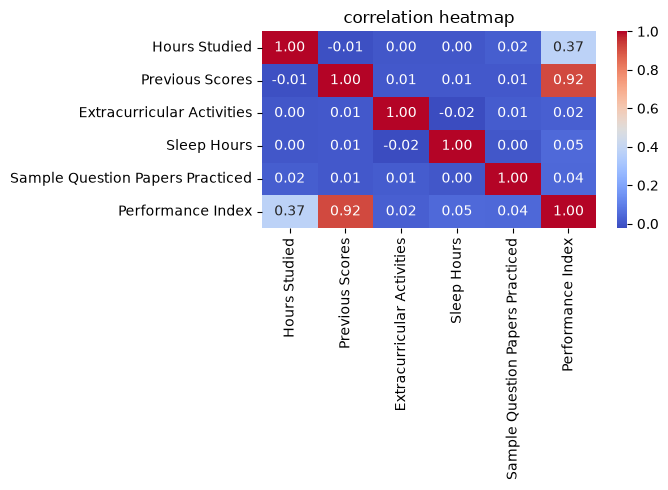

In [12]:
print(df.describe())
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes" : 1 , "No" : 0})
plt.figure(figsize=(7,5))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("correlation heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()


==Simple Linear Regression==
Intercept (b0): 41.43663482653601
Slope (b1): 2.7843004411707217
R2: 0.13160425385996788
RMSE: 17.93919001285204


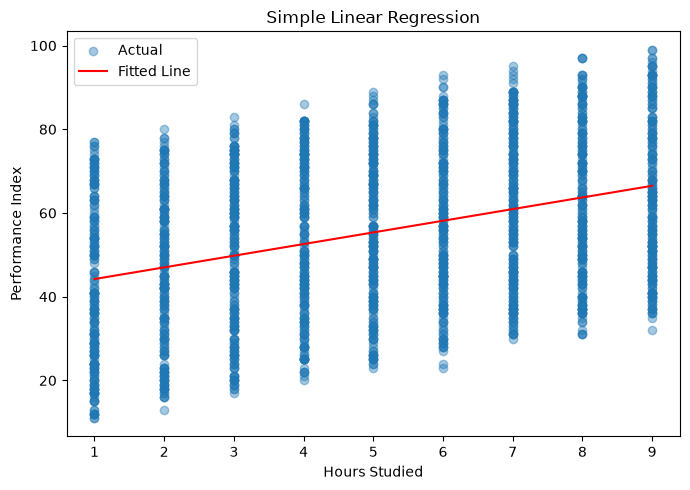

In [13]:
x_simple = df[["Hours Studied"]]
y = df["Performance Index"]

xs_train, xs_test, ys_train, ys_test = train_test_split(
    x_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(xs_train, ys_train)

print("\n==Simple Linear Regression==")
print("Intercept (b0):", simple_model.intercept_)
print("Slope (b1):", simple_model.coef_[0])

ys_pred = simple_model.predict(xs_test)

print("R2:", r2_score(ys_test, ys_pred))
print("RMSE:", np.sqrt(mean_squared_error(ys_test, ys_pred)))

plt.figure(figsize=(7, 5))
plt.scatter(xs_test, ys_test, alpha=0.4, label="Actual")

sorted_x = xs_test.sort_values("Hours Studied")

plt.plot(
    sorted_x,
    simple_model.predict(sorted_x),
    color="red",
    label="Fitted Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_fit.png")
plt.show()

In [14]:

from sklearn.impute import SimpleImputer

# Remove rows where target value is missing
df = df.dropna(subset=["Performance Index"])

# Separate independent and dependent variables
x = df.drop(columns=["Performance Index"])
y = df["Performance Index"]

# Split dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Handle missing values
imputer = SimpleImputer(strategy="median")

x_train = pd.DataFrame(
    imputer.fit_transform(x_train),
    columns=x.columns,
    index=x_train.index
)

x_test = pd.DataFrame(
    imputer.transform(x_test),
    columns=x.columns,
    index=x_test.index
)

# Multiple Linear Regression
multi_model = LinearRegression()
multi_model.fit(x_train, y_train)

print("\n=== Multiple Linear Regression ===")
print("Intercept:", multi_model.intercept_)

print("\nCoefficients:")
for name, coef in zip(x_train.columns, multi_model.coef_):
    print(f"{name:35s} {coef:.4f}")

# Prediction
y_pred = multi_model.predict(x_test)

# Model Evaluation
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

n, p = x_test.shape

if n > p + 1:
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
else:
    adj_r2 = float("nan")

print("\n=== Model Evaluation ===")
print("R2 Score:", r2)
print("Adjusted R2 Score:", adj_r2)
print("RMSE:", rmse)



=== Multiple Linear Regression ===
Intercept: -33.92194621555611

Coefficients:
Hours Studied                       2.8525
Previous Scores                     1.0170
Extracurricular Activities          0.6086
Sleep Hours                         0.4769
Sample Question Papers Practiced    0.1918

=== Model Evaluation ===
R2 Score: 0.9889832909573145
Adjusted R2 Score: 0.9889556663107681
RMSE: 2.020551508505006



                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:10:47   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:                         3.418e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const 

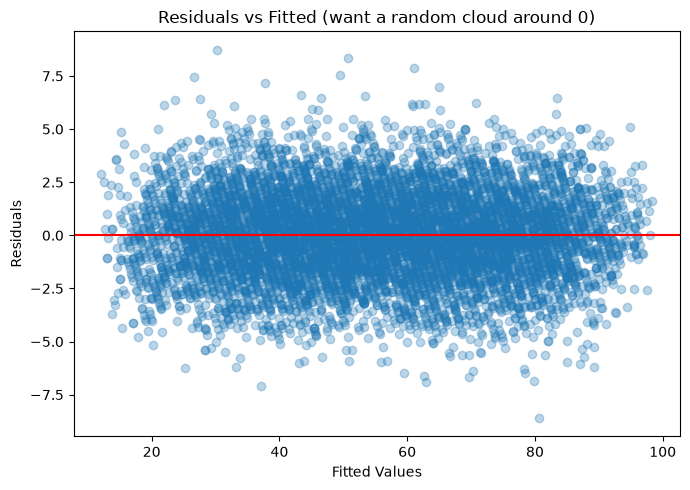

In [15]:
x_train_sm=sm.add_constant(x_train)
ols=sm.OLS(y_train,x_train_sm).fit()
print("\n",ols.summary())
fitted = ols.fittedvalues
resid=ols.resid
plt.figure(figsize=(7,5))
plt.scatter(fitted,resid,alpha=0.3)
plt.axhline(0,color="red")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("03_resid_vs_fitted.png")
plt.show()

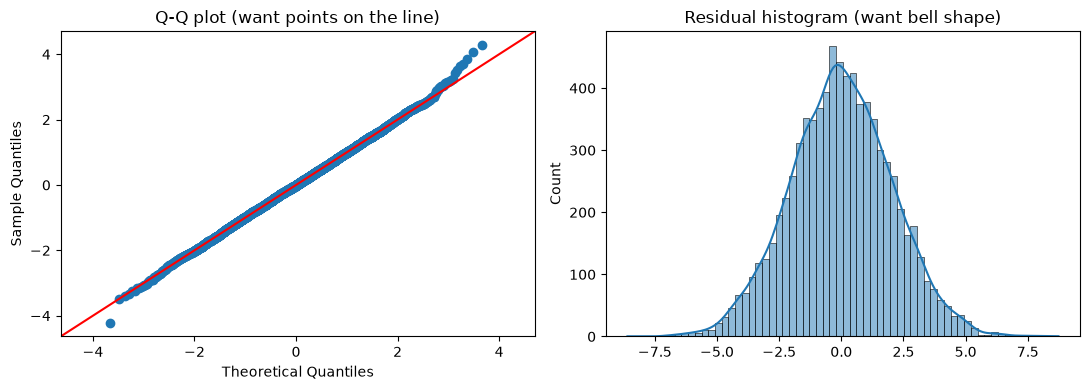

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")

sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")

plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

In [17]:
bp_stat, bp_p, _, _ = het_breuschpagan(resid, x_train_sm)

print("Breusch-Pagan p value:", bp_p)
print("Durbin-Watson:", durbin_watson(resid))

# Convert numpy array into DataFrame
vif_data = pd.DataFrame(x_train_sm)

# Assign feature names
if np.allclose(vif_data.iloc[:, 0], 1):
    vif_data.columns = ["const"] + [
        f"x{i}" for i in range(1, vif_data.shape[1])
    ]
else:
    vif_data.columns = [
        f"x{i}" for i in range(vif_data.shape[1])
    ]

vif = pd.DataFrame({
    "feature": vif_data.columns,
    "VIF": [
        variance_inflation_factor(vif_data.values, i)
        for i in range(vif_data.shape[1])
    ]
})

print("\nVIF:\n", vif[vif["feature"] != "const"])

Breusch-Pagan p value: 0.2396245087909513
Durbin-Watson: 2.033106022504011

VIF:
   feature       VIF
1      x1  1.000387
2      x2  1.000243
3      x3  1.000428
4      x4  1.000461
5      x5  1.000320


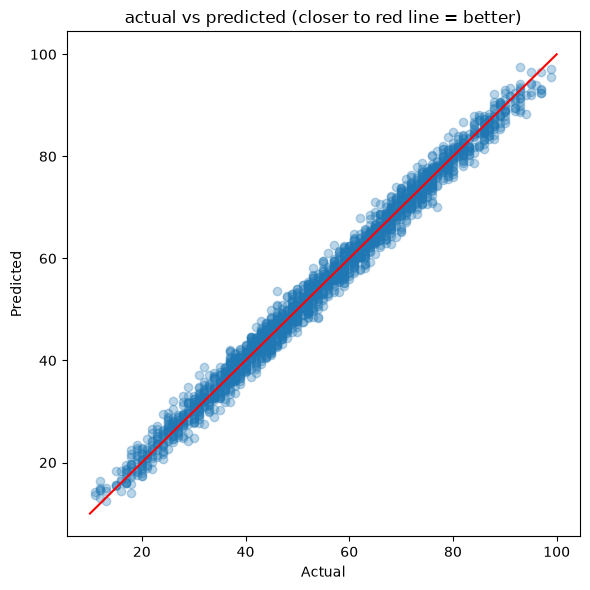

In [18]:
plt.figure(figsize=(6,6))
plt.scatter(y_test , y_pred , alpha=0.3)
plt.plot([y.min() , y.max()] , [y.min() , y.max()] , color = "red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("actual vs predicted (closer to red line = better)")
plt.tight_layout()
plt.savefig("0.5_actual_vs_pred.png")
plt.show()
